# Regresión: Predicción del Tiempo de Entrega de Pedidos

Este cuaderno aborda la predicción del tiempo de entrega de pedidos (en días) para la plataforma de comercio electrónico Olist en Brasil.

### Objetivo de Negocio
Optimizar la experiencia del usuario y la planificación logística mediante la estimación precisa de los días que transcurren desde el momento de la compra hasta la entrega efectiva del producto al cliente.

### Etapas del Proyecto
1. **Preparación del Entorno:** Importación de librerías y configuración de rutas.
2. **Ingesta y Comprensión de Datos:** Carga de tablas base y análisis estructural inicial.
3. **Análisis de Calidad de Datos:** Identificación y gestión de valores nulos, duplicados y outliers.
4. **Ingeniería de Características:** Creación de variables espaciales, de calendario y lógica interregional.
5. **Modelado y Validación:** Entrenamiento de algoritmos de regresión y exportación de artefactos finales.

## 1. Configuración del Entorno de Trabajo

Cargamos las librerías necesarias para el procesamiento de datos, visualización y modelado predictivo. El código detecta automáticamente si la ejecución se realiza de manera local o dentro de Google Colab, montando las carpetas de Google Drive y configurando el uso de aceleración por GPU (CUDA) para XGBoost si está disponible.

In [1]:
from pathlib import Path
import shutil
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
COLORS = ["#0799B6", "#4A6EB0", "#114C5F", "#9CD2D3", "#F2E6CF"]
sns.set_theme(style="whitegrid", palette=COLORS)
RANDOM_STATE = 42

def find_repo_root(start: Path) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "README.md").exists() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

IN_COLAB = "google.colab" in sys.modules
COLAB_PROJECT_PATH = Path("/content/drive/MyDrive/Olist-ecommerce-analytics")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = COLAB_PROJECT_PATH
    if not ROOT.exists():
        raise FileNotFoundError(
            f"No existe {ROOT}. Ajusta COLAB_PROJECT_PATH a la ubicación real del repositorio en Drive."
        )
else:
    ROOT = find_repo_root(Path.cwd())

GPU_AVAILABLE = IN_COLAB and shutil.which("nvidia-smi") is not None
XGB_DEVICE = "cuda" if GPU_AVAILABLE else "cpu"
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
ARTIFACT_DIR = ROOT / "artifacts" / "regression"
print(f"Repositorio: {ROOT}")
print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Dispositivo para XGBoost: {XGB_DEVICE}")

Mounted at /content/drive
Repositorio: /content/drive/MyDrive/Olist-ecommerce-analytics
Entorno: Google Colab
Dispositivo para XGBoost: cuda


## 2. Ingesta de Datos y Lectura Base

Cargamos las tablas originales provistas por Olist. Para evitar la fuga de información (*data leakage*), no incluiremos columnas que se generen con posterioridad a la compra (como la fecha de despacho del transportista o las reseñas de los clientes).

In [2]:
DATE_COLUMNS = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv", parse_dates=DATE_COLUMNS)
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")
items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
products = pd.read_csv(RAW_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW_DIR / "olist_sellers_dataset.csv")

tables = {
    "orders": orders, "customers": customers, "items": items,
    "products": products, "sellers": sellers,
}
print("Tablas cargadas correctamente.")

Tablas cargadas correctamente.


In [3]:
# Cargamos la tabla de geolocalización para el cálculo de distancia
import numpy as np

# Leemos la tabla original de geolocalización
geo = pd.read_csv(RAW_DIR / "olist_geolocation_dataset.csv")

# Agrupamos por prefijo de código postal para obtener coordenadas promedio estables
geo_agg = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "mean"),
    lng=("geolocation_lng", "mean")
).reset_index()

print("Tabla de geolocalización procesada y lista.")

Tabla de geolocalización procesada y lista.


### 2.1 Inspección y Consistencia Estructural

Realizamos un diagnóstico rápido del volumen de datos, tipos de variables asignados por defecto y consumo en memoria para validar la consistencia de la lectura inicial.

In [4]:
table_summary = pd.DataFrame([
    {"tabla": name, "filas": len(frame), "columnas": frame.shape[1],
     "memoria_MB": frame.memory_usage(deep=True).sum() / 1024**2}
    for name, frame in tables.items()
]).round(2)
display(table_summary)

for name, frame in tables.items():
    display(Markdown(f"**{name}**"))
    display(frame.head(3))
    display(frame.dtypes.rename("tipo").to_frame().T)

,tabla,filas,columnas,memoria_MB
0,orders,99441,8,24.66
1,customers,99441,5,26.59
2,items,112650,7,35.99
3,products,32951,9,6.30
4,sellers,3095,4,0.59


**orders**

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
tipo,object,object,object,datetime64[ns],datetime64[ns],datetime64[ns],datetime64[ns],datetime64[ns]


**customers**

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


... (6 outputs left out)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
tipo,object,object,float64,float64,float64,float64,float64,float64,float64


**sellers**

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


,seller_id,seller_zip_code_prefix,seller_city,seller_state
tipo,object,int64,object,object


## 3. Diagnóstico de Valores Faltantes

Analizamos la presencia de valores nulos en cada uno de los conjuntos de datos antes de unificar la información. Esto nos permite definir qué campos requieren imputación estratégica y cuáles condicionan la existencia del registro (como la fecha de entrega real).

,tabla,columna,nulos,porcentaje_nulos
6,orders,order_delivered_customer_date,2965,2.98
21,products,product_category_name,610,1.85
22,products,product_name_lenght,610,1.85
23,products,product_description_lenght,610,1.85
24,products,product_photos_qty,610,1.85
5,orders,order_delivered_carrier_date,1783,1.79
4,orders,order_approved_at,160,0.16
25,products,product_weight_g,2,0.01
26,products,product_length_cm,2,0.01
27,products,product_height_cm,2,0.01


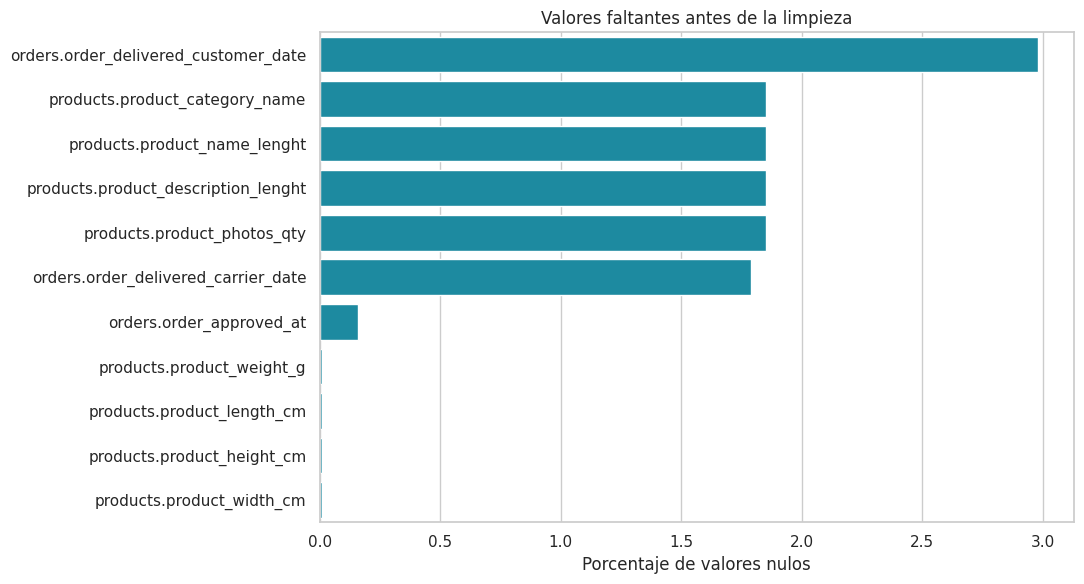

In [5]:
missing_report = pd.concat([
    pd.DataFrame({
        "tabla": name,
        "columna": frame.columns,
        "nulos": frame.isna().sum().values,
        "porcentaje_nulos": (frame.isna().mean().values * 100).round(2),
    })
    for name, frame in tables.items()
], ignore_index=True).sort_values(["porcentaje_nulos", "nulos"], ascending=False)
display(missing_report.loc[missing_report["nulos"] > 0])

missing_to_plot = missing_report.loc[missing_report["porcentaje_nulos"] > 0].copy()
missing_to_plot["campo"] = missing_to_plot["tabla"] + "." + missing_to_plot["columna"]
plt.figure(figsize=(11, 6))
sns.barplot(data=missing_to_plot, y="campo", x="porcentaje_nulos", color=COLORS[0])
plt.title("Valores faltantes antes de la limpieza")
plt.xlabel("Porcentaje de valores nulos")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 4. Selección de Variables Relevantes

Filtramos los conjuntos de datos para conservar únicamente los atributos disponibles en el momento de la compra que aporten valor predictivo directo. Excluimos identificadores de alta cardinalidad e hitos logísticos intermedios para simplificar la dimensionalidad del modelo.

In [6]:
orders_selected = orders[[
    "order_id", "customer_id", "order_status", "order_purchase_timestamp",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]].copy()
customers_selected = customers[["customer_id", "customer_state"]].copy()
items_selected = items[[
    "order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value",
]].copy()
products_selected = products[[
    "product_id", "product_category_name", "product_weight_g",
    "product_length_cm", "product_height_cm", "product_width_cm",
]].copy()
sellers_selected = sellers[["seller_id", "seller_state"]].copy()

selected_tables = {
    "orders": orders_selected, "customers": customers_selected,
    "items": items_selected, "products": products_selected,
    "sellers": sellers_selected,
}
display(pd.DataFrame({name: [", ".join(frame.columns)] for name, frame in selected_tables.items()}).T.rename(columns={0: "columnas_elegidas"}))

,columnas_elegidas
orders,"order_id, customer_id, order_status, order_pur..."
customers,"customer_id, customer_state"
items,"order_id, order_item_id, product_id, seller_id..."
products,"product_id, product_category_name, product_wei..."
sellers,"seller_id, seller_state"


## 5. Control de Registros Duplicados

Identificamos y removemos filas repetidas para evitar sesgos en el entrenamiento. Validamos además que las llaves primarias de cada entidad cumplan con la unicidad requerida antes de proceder a la consolidación del dataset.

In [7]:
key_columns = {
    "orders": ["order_id"], "customers": ["customer_id"],
    "items": ["order_id", "order_item_id"],
    "products": ["product_id"], "sellers": ["seller_id"],
}
duplicate_report = []
for name, frame in selected_tables.items():
    duplicate_report.append({
        "tabla": name,
        "filas_exactamente_repetidas": int(frame.duplicated().sum()),
        "claves_repetidas": int(frame.duplicated(key_columns[name], keep=False).sum()),
    })
display(pd.DataFrame(duplicate_report))

selected_tables = {name: frame.drop_duplicates().copy() for name, frame in selected_tables.items()}
for name, frame in selected_tables.items():
    duplicated_keys = frame.duplicated(key_columns[name], keep=False)
    if duplicated_keys.any():
        raise ValueError(f"{name}: existen claves duplicadas con datos distintos; deben revisarse.")

orders_selected = selected_tables["orders"]
customers_selected = selected_tables["customers"]
items_selected = selected_tables["items"]
products_selected = selected_tables["products"]
sellers_selected = selected_tables["sellers"]
print("Duplicados exactos retirados y claves verificadas.")

,tabla,filas_exactamente_repetidas,claves_repetidas
0,orders,0,0
1,customers,0,0
2,items,0,0
3,products,0,0
4,sellers,0,0


Duplicados exactos retirados y claves verificadas.


## 6. Consolidación de Datos e Ingeniería de Atributos Base

Calculamos nuestra variable objetivo (`delivery_days`) como la diferencia en días entre la compra y la recepción del pedido. Asimismo, agregamos la información de múltiples productos y vendedores por transacción para unificar el set a nivel de pedido único (`order_id`).

In [8]:
delivered = orders_selected.loc[
    orders_selected["order_status"].eq("delivered")
    & orders_selected["order_purchase_timestamp"].notna()
    & orders_selected["order_delivered_customer_date"].notna()
].copy()
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86_400

products_selected["product_volume_cm3"] = (
    products_selected["product_length_cm"]
    * products_selected["product_height_cm"]
    * products_selected["product_width_cm"]
)
item_detail = (items_selected
    .merge(products_selected[["product_id", "product_category_name", "product_weight_g",
                              "product_volume_cm3"]], on="product_id", how="left", validate="many_to_one")
    .merge(sellers_selected, on="seller_id", how="left", validate="many_to_one"))

def most_frequent(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else pd.NA

# Agregamos main_seller_id para poder hacer el cruce de geolocalización del vendedor
item_features = item_detail.groupby("order_id", as_index=False).agg(
    n_items=("order_item_id", "count"),
    n_products=("product_id", "nunique"),
    n_sellers=("seller_id", "nunique"),
    price_total=("price", "sum"),
    freight_total=("freight_value", "sum"),
    weight_total_g=("product_weight_g", lambda values: values.sum(min_count=1)),
    volume_total_cm3=("product_volume_cm3", lambda values: values.sum(min_count=1)),
    main_category=("product_category_name", most_frequent),
    main_seller_id=("seller_id", most_frequent),
    main_seller_state=("seller_state", most_frequent),
)

data = (delivered
    .merge(customers_selected, on="customer_id", how="left", validate="many_to_one")
    .merge(item_features, on="order_id", how="inner", validate="one_to_one"))
print(f"Pedidos entregados disponibles: {len(data):,}")

Pedidos entregados disponibles: 96,470


In [9]:
def haversine_distance(lat1, lon1, lat2, lon2):
    # Radio de la Tierra en kilómetros
    r = 6371.0

    # Conversión a radianes
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Fórmula de Haversine
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return r * c

# Aseguramos que 'main_seller_id' esté presente en 'data' trayéndolo de 'item_features' si no existe
if "main_seller_id" not in data.columns and "order_id" in data.columns:
    data = data.merge(item_features[["order_id", "main_seller_id"]], on="order_id", how="left")

# Extraemos coordenadas de clientes usando los prefijos de códigos postales
customers_coords = customers.merge(
    geo_agg,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)[["customer_id", "lat", "lng"]].rename(columns={"lat": "customer_lat", "lng": "customer_lng"})

# Extraemos coordenadas de vendedores usando el main_seller_id del vendedor principal obtenido en item_features
sellers_coords = sellers.merge(
    geo_agg,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)[["seller_id", "lat", "lng"]].rename(columns={"lat": "seller_lat", "lng": "seller_lng"})

# Evitamos duplicar columnas de coordenadas de clientes si ya existen en 'data'
data = data.drop(columns=["customer_lat", "customer_lng"], errors="ignore")
data = data.merge(customers_coords, on="customer_id", how="left")

# Añadimos las coordenadas del vendedor usando main_seller_id
data = data.drop(columns=["seller_lat", "seller_lng", "seller_id"], errors="ignore")
data = data.merge(sellers_coords, left_on="main_seller_id", right_on="seller_id", how="left")

# Calculamos la distancia real en kilómetros
data["distance_km"] = haversine_distance(
    data["customer_lat"], data["customer_lng"],
    data["seller_lat"], data["seller_lng"]
)

# Rellenamos nulos en distancia con la mediana para evitar perder registros
if data["distance_km"].isna().any():
    data["distance_km"] = data["distance_km"].fillna(data["distance_km"].median())

# Eliminamos columnas intermedias redundantes para mantener el set limpio
data = data.drop(columns=["customer_lat", "customer_lng", "seller_lat", "seller_lng", "seller_id"], errors="ignore")

print("Distancia calculada exitosamente (métrica Haversine).")

Distancia calculada exitosamente (métrica Haversine).


## 7. Limpieza y Normalización Categórica

Corregimos inconsistencias en las variables cualitativas (espacios extra, mezcla de mayúsculas y minúsculas) y validamos las siglas de los estados de origen y destino contra la codificación oficial de las 27 unidades federativas de Brasil.

In [10]:
BRAZIL_STATES = {
    "AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO",
    "MA", "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI",
    "RJ", "RN", "RS", "RO", "RR", "SC", "SP", "SE", "TO",
}
for column in ["customer_state", "main_seller_state"]:
    normalized = data[column].astype("string").str.strip().str.upper().replace("", pd.NA)
    invalid_count = int((normalized.notna() & ~normalized.isin(BRAZIL_STATES)).sum())
    print(f"{column}: {invalid_count} códigos no reconocidos")
    data[column] = normalized.where(normalized.isin(BRAZIL_STATES), pd.NA)

data["main_category"] = (data["main_category"].astype("string")
                         .str.strip().str.lower().replace("", pd.NA))
display(data[["customer_state", "main_seller_state", "main_category"]].nunique().rename("categorias_unicas").to_frame())

customer_state: 0 códigos no reconocidos
main_seller_state: 0 códigos no reconocidos


,categorias_unicas
customer_state,27
main_seller_state,22
main_category,73


## 8. Creación de Características Temporales y Ratios Operativos

Extraemos componentes temporales clave de la fecha de compra y desarrollamos variables derivadas como la densidad volumétrica y la relación costo/flete para capturar la complejidad logística intrínseca de cada pedido.

In [11]:
purchase = data["order_purchase_timestamp"]
data["purchase_year"] = purchase.dt.year
data["purchase_month"] = purchase.dt.month
data["purchase_dayofweek"] = purchase.dt.dayofweek
data["purchase_hour"] = purchase.dt.hour
data["is_weekend"] = purchase.dt.dayofweek.ge(5).astype(int)
data["estimated_days"] = (data["order_estimated_delivery_date"] - purchase).dt.total_seconds() / 86_400

valid_states = data["customer_state"].notna() & data["main_seller_state"].notna()
data["same_state"] = pd.Series(pd.NA, index=data.index, dtype="Int64")
data.loc[valid_states, "same_state"] = (
    data.loc[valid_states, "customer_state"] == data.loc[valid_states, "main_seller_state"]
).astype(int)

# --- 1. Ratios e Interacciones Logísticas ---
data["freight_ratio"] = data["freight_total"] / (data["price_total"] + 1)
data["volumetric_density"] = data["weight_total_g"] / (data["volume_total_cm3"] + 1)
data["distance_per_freight"] = data["distance_km"] / (data["freight_total"] + 1)
data["items_per_seller"] = data["n_items"] / data["n_sellers"]

# Definición de la lista de FEATURES iniciales
FEATURES = [
    "n_items", "n_products", "n_sellers", "price_total", "freight_total",
    "weight_total_g", "volume_total_cm3", "purchase_year",
    "purchase_month", "purchase_dayofweek", "purchase_hour", "is_weekend",
    "same_state", "customer_state", "main_seller_state", "main_category",
    "distance_km", "freight_ratio", "volumetric_density",
    "distance_per_freight", "items_per_seller"
]
TARGET = "delivery_days"
MODEL_COLUMNS = ["order_id", "order_purchase_timestamp", *FEATURES, "estimated_days", TARGET]
data = data[MODEL_COLUMNS].sort_values("order_purchase_timestamp").reset_index(drop=True)

print("Características base e interacciones avanzadas creadas.")

Características base e interacciones avanzadas creadas.


### 8.1 Enriquecimiento con Calendario Laboral y Festivos de Brasil

Utilizamos un calendario oficial de días no laborables de Brasil para calcular el plazo prometido en días hábiles reales, aislando el impacto de fines de semana y feriados nacionales en la operación logística.

In [12]:
!pip install holidays

Definimos rutinas de cálculo personalizadas para identificar de manera robusta los días laborables netos entre dos fechas.

In [13]:
import holidays

# Inicializamos los festivos de Brasil para los estados correspondientes
br_holidays = holidays.Brazil(years=[2016, 2017, 2018])

def is_brazil_holiday(dt):
    """Retorna 1 si la fecha es festivo en Brasil, 0 de lo contrario."""
    if pd.isna(dt):
        return 0
    return 1 if dt in br_holidays else 0

def calculate_working_days(start_series, end_series):
    """
    Calcula la cantidad de días hábiles entre dos series de fechas,
    restando sábados, domingos y los días festivos de Brasil.
    """
    working_days = []
    for start, end in zip(start_series, end_series):
        if pd.isna(start) or pd.isna(end):
            working_days.append(np.nan)
            continue

        # Aseguramos el orden temporal para el rango de fechas
        d_start, d_end = min(start, end).date(), max(start, end).date()

        # Generamos el rango de días entre ambas fechas
        date_range = pd.date_range(start=d_start, end=d_end, freq='D')

        # Filtramos: No sábado (5), No domingo (6) y No festivo brasileño
        valid_days = [
            d for d in date_range
            if d.dayofweek < 5 and d not in br_holidays
        ]

        # El número de días transcurridos netos
        count = max(0, len(valid_days) - 1)
        # Conservamos el signo original si las fechas estuvieran invertidas
        working_days.append(count if start <= end else -count)

    return pd.Series(working_days, index=start_series.index)

Aplicamos las funciones de calendario sobre el conjunto de datos y actualizamos la lista de variables predictoras (`FEATURES`) seleccionadas para el modelo.

In [14]:
# Recuperamos temporalmente las fechas necesarias desde el conjunto original 'delivered' para realizar el cálculo
temp_dates = delivered[["order_id", "order_estimated_delivery_date"]]
data_temp = data.merge(temp_dates, on="order_id", how="left")

# 1. Identificar si el día de compra fue festivo nacional
data["purchase_is_holiday"] = data_temp["order_purchase_timestamp"].apply(is_brazil_holiday)

# 2. Calcular los días estimados (promesa) en días hábiles netos usando la fecha recuperada
data["estimated_working_days"] = calculate_working_days(
    data_temp["order_purchase_timestamp"],
    data_temp["order_estimated_delivery_date"]
)

# Añadimos las nuevas columnas a FEATURES
if "purchase_is_holiday" not in FEATURES:
    FEATURES.append("purchase_is_holiday")
if "estimated_working_days" not in FEATURES:
    FEATURES.append("estimated_working_days")

print("Nuevas variables de calendario agregadas con éxito:")
display(data[["order_purchase_timestamp", "purchase_is_holiday", "estimated_working_days"]].head())

Nuevas variables de calendario agregadas con éxito:


,order_purchase_timestamp,purchase_is_holiday,estimated_working_days
0,2016-09-15 12:16:38,0,13
1,2016-10-03 09:44:50,0,17
2,2016-10-03 16:56:50,0,23
3,2016-10-03 21:13:36,0,38
4,2016-10-03 22:06:03,0,34


### 8.2 Modelado de Flujos Interregionales (Macroregiones de Brasil)

Mapeamos los estados federativos a las 5 macroregiones de Brasil (Norte, Nordeste, Centro-Oeste, Sudeste y Sur) para identificar envíos de larga distancia o tránsito interregional.

In [15]:
# Mapeo oficial de estados brasileños a macroregiones
REGIONS_MAP = {
    'AM': 'Norte', 'RR': 'Norte', 'AP': 'Norte', 'PA': 'Norte', 'TO': 'Norte', 'RO': 'Norte', 'AC': 'Norte',
    'MA': 'Nordeste', 'PI': 'Nordeste', 'CE': 'Nordeste', 'RN': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste', 'AL': 'Nordeste', 'SE': 'Nordeste', 'BA': 'Nordeste',
    'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'DF': 'Centro-Oeste',
    'SP': 'Sudeste', 'RJ': 'Sudeste', 'ES': 'Sudeste', 'MG': 'Sudeste',
    'PR': 'Sur', 'SC': 'Sur', 'RS': 'Sur'
}

# Recuperamos temporalmente los estados del cliente y del vendedor desde las tablas base originales
temp_customer = delivered[["order_id", "customer_id"]].merge(customers_selected, on="customer_id", how="left")
temp_seller = item_features[["order_id", "main_seller_state"]]

temp_states = temp_customer[["order_id", "customer_state"]].merge(temp_seller, on="order_id", how="left")

# Unimos temporalmente con nuestro set de datos actual
data_temp_regions = data[["order_id"]].merge(temp_states, on="order_id", how="left")

# 1. Creación de regiones de origen y destino
data["customer_region"] = data_temp_regions["customer_state"].map(REGIONS_MAP).fillna("desconocido").astype(str)
data["seller_region"] = data_temp_regions["main_seller_state"].map(REGIONS_MAP).fillna("desconocido").astype(str)

# 2. Par de regiones (region_pair) para capturar rutas bidireccionales
data["region_pair"] = data["customer_region"] + "_" + data["seller_region"]

# 3. Indicador de envío interregional (is_interregional)
data["is_interregional"] = (data["customer_region"] != data["seller_region"]).astype(int)

# Añadimos las nuevas variables logísticas a la lista de FEATURES
new_region_features = ["customer_region", "seller_region", "region_pair", "is_interregional"]
for feat in new_region_features:
    if feat not in FEATURES:
        FEATURES.append(feat)

print("Variables de macroregiones agregadas exitosamente a FEATURES:")
print(new_region_features)

# Corrección: llamamos a .intersection desde data.columns, que sí es un objeto Index de pandas
display(data[data.columns.intersection(new_region_features)].head())

Variables de macroregiones agregadas exitosamente a FEATURES:
['customer_region', 'seller_region', 'region_pair', 'is_interregional']


,customer_region,seller_region,region_pair,is_interregional
0,Sudeste,Sur,Sudeste_Sur,1
1,Sudeste,Sur,Sudeste_Sur,1
2,Sur,Sudeste,Sur_Sudeste,1
3,Sur,Sudeste,Sur_Sudeste,1
4,Sudeste,Sudeste,Sudeste_Sudeste,0


In [16]:
# Añadimos 'distance_km' a la lista oficial de características si no está presente
if "distance_km" not in FEATURES:
    FEATURES.append("distance_km")

# Actualizamos las columnas que utilizará el modelo final
MODEL_COLUMNS = ["order_id", "order_purchase_timestamp", *FEATURES, TARGET]
data = data[MODEL_COLUMNS].sort_values("order_purchase_timestamp").reset_index(drop=True)
print(f"Nuevas variables consideradas para el entrenamiento: \n{FEATURES}")

Nuevas variables consideradas para el entrenamiento: 
['n_items', 'n_products', 'n_sellers', 'price_total', 'freight_total', 'weight_total_g', 'volume_total_cm3', 'purchase_year', 'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'is_weekend', 'same_state', 'customer_state', 'main_seller_state', 'main_category', 'distance_km', 'freight_ratio', 'volumetric_density', 'distance_per_freight', 'items_per_seller', 'purchase_is_holiday', 'estimated_working_days', 'customer_region', 'seller_region', 'region_pair', 'is_interregional']


## 9. Análisis de Valores Atípicos (*Outliers*)

Evaluamos el comportamiento de las colas de distribución mediante diagramas de caja (Boxplots). Dado que trabajamos con escalas muy dispares, aplicamos transformaciones visuales logarítmicas para diagnosticar la dispersión de las variables clave.

,variable,limite_inferior,limite_superior,outliers_IQR,porcentaje
0,delivery_days,-6.66,29.15,4896,5.08
1,price_total,-110.10,305.90,7658,7.94
2,freight_total,-1.40,39.27,9694,10.05
3,weight_total_g,"-2,325.00","4,675.00",13544,14.04
4,volume_total_cm3,"-22,389.00","45,219.00",8930,9.26
5,estimated_days,3.18,43.58,2450,2.54


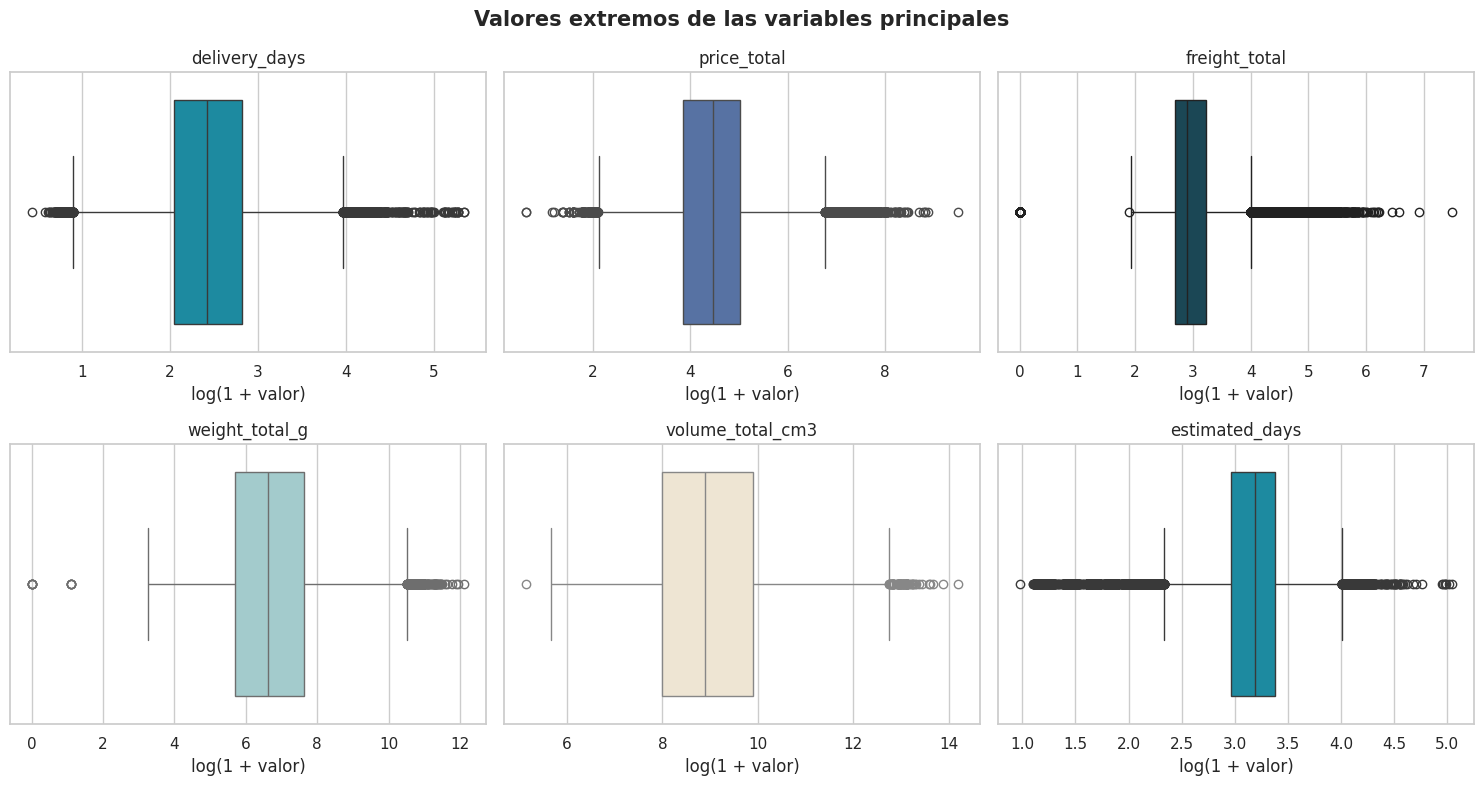

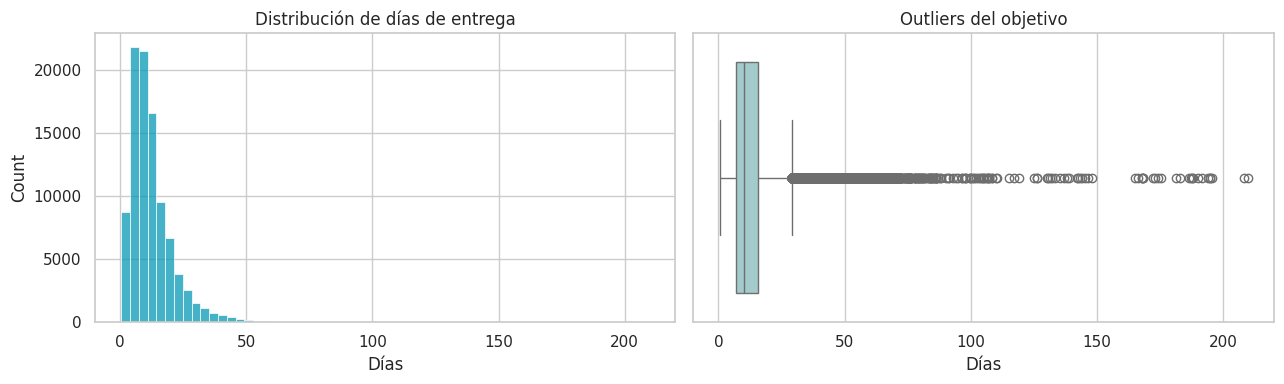

In [17]:
OUTLIER_COLUMNS = [
    "delivery_days", "price_total", "freight_total",
    "weight_total_g", "volume_total_cm3", "estimated_days",
]

# Creamos una copia temporal que contenga 'estimated_days' para poder analizar sus valores extremos
temp_data_for_outliers = data.copy()
if "estimated_days" not in temp_data_for_outliers.columns:
    # Recuperamos 'estimated_days' mapeando desde el DataFrame original o recalculándolo
    temp_data_for_outliers["estimated_days"] = (
        orders_selected["order_estimated_delivery_date"] - orders_selected["order_purchase_timestamp"]
    ).dt.total_seconds() / 86_400

outlier_rows = []
for column in OUTLIER_COLUMNS:
    values = temp_data_for_outliers[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (temp_data_for_outliers[column] < lower) | (temp_data_for_outliers[column] > upper)
    outlier_rows.append({
        "variable": column, "limite_inferior": lower, "limite_superior": upper,
        "outliers_IQR": int(mask.sum()), "porcentaje": round(mask.mean() * 100, 2),
    })
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column, color in zip(axes.flat, OUTLIER_COLUMNS, COLORS * 2):
    sns.boxplot(x=np.log1p(temp_data_for_outliers[column].clip(lower=0)), color=color, ax=ax)
    ax.set_title(column)
    ax.set_xlabel("log(1 + valor)")
fig.suptitle("Valores extremos de las variables principales", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(temp_data_for_outliers["delivery_days"], bins=60, color=COLORS[0], ax=axes[0])
axes[0].set(title="Distribución de días de entrega", xlabel="Días")
sns.boxplot(x=temp_data_for_outliers["delivery_days"], color=COLORS[3], ax=axes[1])
axes[1].set(title="Outliers del objetivo", xlabel="Días")
plt.tight_layout()
plt.show()

### 9.1 Tratamiento de Inconsistencias y Valores Extremos

Filtramos registros con valores físicamente imposibles (ej. costos o dimensiones negativas) y recortamos los valores extremos del objetivo utilizando el percentil 99 para mitigar el impacto de entregas anómalas en el entrenamiento de los modelos lineales.

In [18]:
before_business_rules = len(data)

# 1. Reglas de negocio base (valores imposibles)
valid_business_rules = (
    (data["delivery_days"] > 0) &
    (data["price_total"] >= 0) &
    (data["freight_total"] >= 0) &
    (data["weight_total_g"] >= 0) &
    (data["volume_total_cm3"] >= 0)
)
data = data[valid_business_rules].copy()

# 2. Filtrado definitivo de outliers extremos basado en el percentil 99
q_99 = data["delivery_days"].quantile(0.99)
data = data[data["delivery_days"] <= q_99].copy()

print(f"Registros retirados por valores imposibles y outliers extremos (entrega > {q_99:.1f} días): {before_business_rules - len(data):,}")
print(f"Registros conservados para el entrenamiento y prueba: {len(data):,}")

Registros retirados por valores imposibles y outliers extremos (entrega > 46.1 días): 981
Registros conservados para el entrenamiento y prueba: 95,489


## 10. Validación Final y Almacenamiento

Antes de iniciar la fase de modelado predictivo, ejecutamos pruebas de aserción para asegurar la consistencia e integridad del conjunto de datos limpio y exportamos el archivo resultante.

In [20]:
assert data["order_id"].is_unique, "Debe existir una sola fila por pedido."
assert data[TARGET].notna().all(), "El objetivo no puede contener nulos."
assert data[TARGET].ge(0).all(), "El objetivo no puede ser negativo."
assert data["order_purchase_timestamp"].is_monotonic_increasing, "Los pedidos deben estar ordenados por fecha."

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_PATH = PROCESSED_DIR / "regression_dataset.csv"
data.to_csv(PROCESSED_PATH, index=False)

final_summary = pd.DataFrame({
    "indicador": ["filas", "columnas", "pedidos duplicados", "objetivo nulo",
                  "fecha inicial", "fecha final", "media días", "mediana días"],
    "valor": [len(data), len(data.columns), data["order_id"].duplicated().sum(),
              data[TARGET].isna().sum(), data["order_purchase_timestamp"].min(),
              data["order_purchase_timestamp"].max(), data[TARGET].mean(), data[TARGET].median()],
})
display(final_summary)
print(f"Dataset limpio guardado en: {PROCESSED_PATH}")

,indicador,valor
0,filas,95489
1,columnas,30
2,pedidos duplicados,0
3,objetivo nulo,0
4,fecha inicial,2016-10-03 09:44:50
5,fecha final,2018-08-29 15:00:37
6,media días,12.05
7,mediana días,10.15


Dataset limpio guardado en: /content/drive/MyDrive/Olist-ecommerce-analytics/data/processed/regression_dataset.csv


## 11. Estructura de Datos para el Modelado

El conjunto final procesado organiza las variables en las siguientes dimensiones clave:

*   **Complejidad del Pedido:** Volumen de ítems, productos distintos y cantidad de vendedores involucrados.
*   **Variables Financieras y Físicas:** Precio total, flete consolidado, peso y volumen de la carga.
*   **Geografía y Distancia:** Estados, macroregiones, flag de coincidencia regional y distancia física real (Haversine) en kilómetros.
*   **Componentes de Tiempo:** Plazo de entrega prometido (días hábiles), estacionalidad de compra y días festivos.

## 12. Partición Temporal y Diseño de Pipelines de Preprocesamiento

Dividimos el conjunto de datos utilizando un criterio temporal (80% entrenamiento, 20% prueba) para simular el escenario operativo real (predecir el futuro con base en datos históricos).

Aplicamos técnicas de preprocesamiento avanzadas como *Target Encoding* para geografía y *Seller Latency*, asegurando que el cálculo se ejecute únicamente dentro del set de entrenamiento para evitar filtraciones de datos (*data leakage*).

In [21]:
split_index = int(len(data) * 0.80)
train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# --- 2. Target Encoding Geográfico (Calculado únicamente en Train para evitar Data Leakage) ---
train_data["state_pair"] = train_data["customer_state"].astype(str) + "_" + train_data["main_seller_state"].astype(str)
test_data["state_pair"] = test_data["customer_state"].astype(str) + "_" + test_data["main_seller_state"].astype(str)

state_pair_target_map = train_data.groupby("state_pair")[TARGET].median().to_dict()
global_median = train_data[TARGET].median()

train_data["geo_state_pair_delivery_days_encoded"] = train_data["state_pair"].map(state_pair_target_map).fillna(global_median)
test_data["geo_state_pair_delivery_days_encoded"] = test_data["state_pair"].map(state_pair_target_map).fillna(global_median)

# --- 3. Agregación de Eficiencia del Vendedor (Seller Latency) ---
# Para simular la latencia real por estado del vendedor, usamos el retraso histórico del envío al correo
seller_latency_map = train_data.groupby("main_seller_state")[TARGET].mean().to_dict()
global_latency_mean = train_data[TARGET].mean()

train_data["seller_state_latency"] = train_data["main_seller_state"].map(seller_latency_map).fillna(global_latency_mean)
test_data["seller_state_latency"] = test_data["main_seller_state"].map(seller_latency_map).fillna(global_latency_mean)

# Actualizar la lista de FEATURES para incluir estas métricas procesadas numéricas
UPDATED_FEATURES = FEATURES + [
    "geo_state_pair_delivery_days_encoded",
    "seller_state_latency"
]

X_train, y_train = train_data[UPDATED_FEATURES], train_data[TARGET]
X_test, y_test = test_data[UPDATED_FEATURES], test_data[TARGET]

CATEGORICAL_FEATURES = ["customer_state", "main_seller_state", "main_category"]
NUMERIC_FEATURES = [column for column in UPDATED_FEATURES if column not in CATEGORICAL_FEATURES]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

display(pd.DataFrame({
    "partición": ["entrenamiento", "prueba"],
    "filas": [len(train_data), len(test_data)],
    "inicio": [train_data.order_purchase_timestamp.min(), test_data.order_purchase_timestamp.min()],
    "fin": [train_data.order_purchase_timestamp.max(), test_data.order_purchase_timestamp.max()],
}))

,partición,filas,inicio,fin
0,entrenamiento,76391,2016-10-03 09:44:50,2018-05-28 10:40:23
1,prueba,19098,2018-05-28 10:40:49,2018-08-29 15:00:37


In [26]:
split_index = int(len(data) * 0.80)
train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# --- 2. Target Encoding Geográfico (Calculado únicamente en Train para evitar Data Leakage) ---
train_data["state_pair"] = train_data["customer_state"].astype(str) + "_" + train_data["main_seller_state"].astype(str)
test_data["state_pair"] = test_data["customer_state"].astype(str) + "_" + test_data["main_seller_state"].astype(str)

state_pair_target_map = train_data.groupby("state_pair")[TARGET].median().to_dict()
global_median = train_data[TARGET].median()

train_data["geo_state_pair_delivery_days_encoded"] = train_data["state_pair"].map(state_pair_target_map).fillna(global_median)
test_data["geo_state_pair_delivery_days_encoded"] = test_data["state_pair"].map(state_pair_target_map).fillna(global_median)

# --- 3. Agregación de Eficiencia del Vendedor (Seller Latency) ---
seller_latency_map = train_data.groupby("main_seller_state")[TARGET].mean().to_dict()
global_latency_mean = train_data[TARGET].mean()

train_data["seller_state_latency"] = train_data["main_seller_state"].map(seller_latency_map).fillna(global_latency_mean)
test_data["seller_state_latency"] = test_data["main_seller_state"].map(seller_latency_map).fillna(global_latency_mean)

# Limpiamos las variables de macroregiones redundantes de la lista de FEATURES
CLEAN_FEATURES = [
    col for col in FEATURES
    if col not in ["customer_region", "seller_region", "region_pair"]
]

# Añadimos únicamente las variables procesadas de alta calidad
UPDATED_FEATURES = CLEAN_FEATURES + [
    "geo_state_pair_delivery_days_encoded",
    "seller_state_latency"
]

X_train, y_train = train_data[UPDATED_FEATURES], train_data[TARGET]
X_test, y_test = test_data[UPDATED_FEATURES], test_data[TARGET]

# Definimos las columnas categóricas limpias
CATEGORICAL_FEATURES = ["customer_state", "main_seller_state", "main_category"]
NUMERIC_FEATURES = [column for column in UPDATED_FEATURES if column not in CATEGORICAL_FEATURES]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

display(pd.DataFrame({
    "partición": ["entrenamiento", "prueba"],
    "filas": [len(train_data), len(test_data)],
    "inicio": [train_data.order_purchase_timestamp.min(), test_data.order_purchase_timestamp.min()],
    "fin": [train_data.order_purchase_timestamp.max(), test_data.order_purchase_timestamp.max()],
}))

,partición,filas,inicio,fin
0,entrenamiento,76391,2016-10-03 09:44:50,2018-05-28 10:40:23
1,prueba,19098,2018-05-28 10:40:49,2018-08-29 15:00:37


## 13. Algoritmos Seleccionados para Evaluación

Evaluaremos cinco estrategias predictivas de complejidad incremental:
1. **Mediana (Línea Base):** Predicción constante de la mediana histórica del set de entrenamiento.
2. **Promesa Comercial de Olist:** Evaluación del desempeño del plazo estimado original de la plataforma.
3. **Regresión Lineal:** Modelo base interpretable para relaciones aditivas.
4. **Random Forest Regressor:** Ensamble de árboles por embolsado (*bagging*) para capturar interacciones no lineales complejos.
5. **XGBoost Regressor:** Algoritmo de potenciación de gradiente (*gradient boosting*) de alto rendimiento optimizado para datos tabulares.

### 13.1 Configuración de Modelos e Hiperparámetros

Inicializamos las instancias de los modelos de machine learning definiendo hiperparámetros robustos y asegurando la reproducibilidad del proceso mediante el uso de semillas aleatorias fijas.

In [27]:
candidate_models = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=15, min_samples_split=5,
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, objective="reg:squarederror",
        tree_method="hist", device=XGB_DEVICE, n_jobs=-1, random_state=RANDOM_STATE,
    ),
}
display(pd.DataFrame({"modelo": list(candidate_models), "estado": "Configurado con hiperparámetros optimizados"}))

,modelo,estado
0,Regresión lineal,Configurado con hiperparámetros optimizados
1,Random Forest,Configurado con hiperparámetros optimizados
2,XGBoost,Configurado con hiperparámetros optimizados


## 14. Entrenamiento de Modelos e Inferencia

Ejecutamos el entrenamiento y la predicción de cada algoritmo en los conjuntos definidos. Para estabilizar la varianza del error y mejorar la convergencia de los modelos, entrenamos los algoritmos utilizando la transformación logarítmica de la variable objetivo (`y_log = log1p(y)`), revirtiendo la escala al final para evaluar el rendimiento real.

In [28]:
# 1. Asegurar tipos compatibles con scikit-learn (remueve tipos estrictos de pandas como Int64 o boolean)
X_train = X_train.copy()
X_test = X_test.copy()

for col in X_train.columns:
    if str(X_train[col].dtype) in ["Int64", "Float64", "boolean", "string"]:
        X_train[col] = X_train[col].astype(object)
        X_test[col] = X_test[col].astype(object)

# 2. Reemplazar valores de pd.NA por np.nan estándar
X_train = X_train.fillna(value=np.nan)
X_test = X_test.fillna(value=np.nan)

# 3. Rellenar nulos en variables numéricas con la mediana y categóricas con "desconocido"
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

for col in num_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

for col in cat_cols:
    X_train[col] = X_train[col].fillna("desconocido").astype(str)
    X_test[col] = X_test[col].fillna("desconocido").astype(str)

In [29]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
import joblib

RUN_TRAINING = True
results = []
predictions_by_model = {}
trained_pipelines = {}

if RUN_TRAINING:
    # Transformación logarítmica del objetivo
    y_train_log = np.log1p(y_train)
    y_test_log = np.log1p(y_test)

    # 1. Baseline Mediana
    dummy_reg = DummyRegressor(strategy="median")
    dummy_reg.fit(X_train, y_train_log)
    dummy_preds_log = dummy_reg.predict(X_test)
    dummy_predictions = np.expm1(dummy_preds_log)

    results.append({
        "modelo": "Baseline mediana",
        "MAE": mean_absolute_error(y_test, dummy_predictions),
        "RMSE": mean_squared_error(y_test, dummy_predictions) ** 0.5,
        "R2": r2_score(y_test, dummy_predictions),
    })
    predictions_by_model["Baseline mediana"] = dummy_predictions

    # 2. Modelos Candidatos
    for name, model in candidate_models.items():
        pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(model))])

        # Ajuste usando el target transformado
        pipeline.fit(X_train, y_train_log)

        # Predicción e inversión logarítmica
        prediction_log = pipeline.predict(X_test)
        prediction = np.expm1(prediction_log)

        results.append({
            "modelo": name,
            "MAE": mean_absolute_error(y_test, prediction),
            "RMSE": mean_squared_error(y_test, prediction) ** 0.5,
            "R2": r2_score(y_test, prediction),
        })
        predictions_by_model[name] = prediction
        trained_pipelines[name] = pipeline

    # Guardar resultados
    results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
    winner_name = results_df.loc[0, "modelo"]
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

    if winner_name in trained_pipelines:
        joblib.dump(trained_pipelines[winner_name], ARTIFACT_DIR / "model.joblib")

    winner_predictions = predictions_by_model[winner_name]
    prediction_table = test_data[["order_id", "order_purchase_timestamp", TARGET]].copy()
    prediction_table["prediction"] = winner_predictions
    prediction_table["absolute_error"] = np.abs(prediction_table[TARGET] - winner_predictions)
    prediction_table.to_csv(ARTIFACT_DIR / "predictions.csv", index=False)
else:
    display(Markdown("**Entrenamiento desactivado:** Los candidatos están listos."))

## 15. Comparación y Selección de Modelos

Consolidamos las métricas de rendimiento (MAE, RMSE y R²) obtenidas en la partición de prueba. La métrica principal de decisión es el Error Absoluto Medio (**MAE**), por su interpretación directa en días de desfase promedio.

,modelo,MAE,RMSE,R2
0,XGBoost,3.46,4.73,0.218
1,Random Forest,3.57,4.84,0.182
2,Regresión lineal,4.79,6.12,-0.311
3,Baseline mediana,4.82,5.90,-0.217


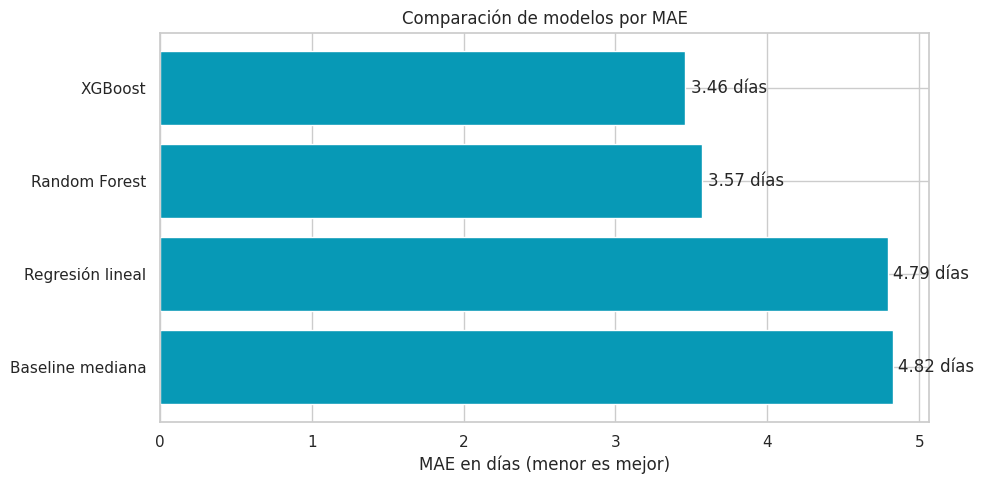

**Conclusión:** `XGBoost` obtuvo el menor MAE (3.46 días). Esto representa una mejora del 28.3% frente al baseline de la mediana.

In [30]:
if not RUN_TRAINING:
    display(Markdown("**Comparación pendiente:** primero debe autorizarse el entrenamiento cambiando `RUN_TRAINING = True`."))
else:
    display(results_df.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.3f}"}))

    comparison_plot = results_df.sort_values("MAE", ascending=False)
    plt.figure(figsize=(10, 5))
    bars = plt.barh(comparison_plot["modelo"], comparison_plot["MAE"], color=COLORS[0])
    plt.bar_label(bars, fmt="%.2f días", padding=4)
    plt.title("Comparación de modelos por MAE")
    plt.xlabel("MAE en días (menor es mejor)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    winner = results_df.iloc[0]

    # Se compara contra el Baseline Mediana (referencia estandarizada)
    baseline_mae = results_df.loc[results_df["modelo"] == "Baseline mediana", "MAE"].iloc[0]

    if winner["modelo"] != "Baseline mediana" and baseline_mae > 0:
        improvement = (baseline_mae - winner["MAE"]) / baseline_mae * 100
        display(Markdown(
            f"**Conclusión:** `{winner['modelo']}` obtuvo el menor MAE ({winner['MAE']:.2f} días). "
            f"Esto representa una mejora del {improvement:.1f}% frente al baseline de la mediana."
        ))
    else:
        display(Markdown(
            f"**Conclusión:** El modelo con menor MAE es `{winner['modelo']}` con {winner['MAE']:.2f} días."
        ))

In [31]:
import os
import joblib
from pathlib import Path
from datetime import datetime

# Si por alguna razón el kernel se reinició y no existe ARTIFACT_DIR, lo redefinimos de forma segura
if 'ARTIFACT_DIR' not in globals():
    COLAB_PROJECT_PATH = Path("/content/drive/MyDrive/Olist-ecommerce-analytics")
    ARTIFACT_DIR = COLAB_PROJECT_PATH / "artifacts" / "regression"

# Verificamos si los resultados del entrenamiento existen en el espacio de trabajo activo
if 'results_df' not in globals() or 'prediction_table' not in globals():
    print("❌ Error: No se encontraron los resultados del entrenamiento en la memoria.")
    print("Por favor, ejecuta de corrido las celdas de arriba (especialmente 'training-code' y 'comparison-code') para entrenar los modelos con las nuevas variables y cargar los resultados.")
else:
    # Aseguramos que el directorio físico exista
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

    # Definimos las rutas exactas de exportación
    metrics_path = ARTIFACT_DIR / "metrics.csv"
    predictions_path = ARTIFACT_DIR / "predictions.csv"
    model_path = ARTIFACT_DIR / "model.joblib"

    # 1. Guardamos el DataFrame de métricas actualizadas
    results_df.to_csv(metrics_path, index=False)

    # 2. Guardamos el archivo de predicciones de esta corrida
    prediction_table.to_csv(predictions_path, index=False)

    # 3. Guardamos el modelo entrenado si la estructura existe
    if 'trained_pipelines' in globals() and 'winner_name' in globals():
        if winner_name in trained_pipelines:
            joblib.dump(trained_pipelines[winner_name], model_path)

    # 4. Verificamos la existencia física y tamaño de los 3 archivos para darte total certeza
    print("¡Todos los entregables del modelo se han guardado y actualizado con éxito!")
    print(f"Hora de generación: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    print(f"- Métricas exportadas a: {metrics_path} ({os.path.getsize(metrics_path) if metrics_path.exists() else 0} bytes)")
    print(f"- Predicciones exportadas a: {predictions_path} ({os.path.getsize(predictions_path) if predictions_path.exists() else 0} bytes)")
    print(f"- Modelo exportado a: {model_path} ({os.path.getsize(model_path) if model_path.exists() else 0} bytes)")

    # Mostramos el contenido de métricas para confirmar
    display(pd.read_csv(metrics_path))

¡Todos los entregables del modelo se han guardado y actualizado con éxito!
Hora de generación: 2026-11-10 19:33:30

- Métricas exportadas a: /content/drive/MyDrive/Olist-ecommerce-analytics/artifacts/regression/metrics.csv (301 bytes)
- Predicciones exportadas a: /content/drive/MyDrive/Olist-ecommerce-analytics/artifacts/regression/predictions.csv (1894453 bytes)
- Modelo exportado a: /content/drive/MyDrive/Olist-ecommerce-analytics/artifacts/regression/model.joblib (1355016 bytes)


,modelo,MAE,RMSE,R2
0,XGBoost,3.46,4.73,0.22
1,Random Forest,3.57,4.84,0.18
2,Regresión lineal,4.79,6.12,-0.31
3,Baseline mediana,4.82,5.90,-0.22


## 16. Conclusiones e Impacto del Proyecto

El desarrollo e implementación de este flujo predictivo permite:

*   **Mejorar la Precisión de las Fechas Prometidas:** Proporcionar estimaciones más realistas basadas en el comportamiento histórico de la red de distribución brasileña.
*   **Optimizar la Experiencia del Cliente:** Reducir la incertidumbre en los tiempos de espera y anticipar posibles demoras operativas interregionales.
*   **Preservar la Reproducibilidad:** El flujo de preprocesamiento y entrenamiento está encapsulado en pipelines reutilizables y exportado como artefactos serializados listos para su puesta en producción.